In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [8]:
df = pd.read_csv('regression_project/regrassion_dataset.csv')

cdf = df[['Area', 'Parking', 'Warehouse', 'Elevator',
          'Room', 'Address', 'Price', 'Price(USD)']]

cdf = cdf.dropna(subset=['Area', 'Price'])

In [9]:
cdf['Area'] = (
    cdf['Area']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)

cdf['Area'] = pd.to_numeric(cdf['Area'], errors='coerce')
cdf = cdf.dropna(subset=['Area'])
cdf = cdf.reset_index(drop=True)

In [10]:
cdf = cdf.dropna(subset=['Address'])
cdf = cdf.reset_index(drop=True)


cdf['Address'] = (
    cdf['Address']
    .astype(str)
    .str.strip()
    .str.lower()
)

In [11]:
import re

def normalize_and_clean_address(address: str) -> str:
    if not isinstance(address, str):
        return ""
        
    text = address.lower().strip()
    text = re.sub(r"[^\w\sآ-ی]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

cdf['Address'] = cdf['Address'].apply(normalize_and_clean_address)


In [12]:
def normalize_directions(text):
    if not isinstance(text, str):
        return text

    t = text.lower()

    t = re.sub(r'\b(north|northern|northen|shomal)\b', 'shomali', t)
    t = re.sub(r'\b(south|southern|southen|jonoub|jnoubi|jonoob|jonoobi)\b', 'jonoubi', t)
    t = re.sub(r'\b(east|eastern|shargh|shargi)\b', 'sharghi', t)
    t = re.sub(r'\b(west|western|westen|gharb)\b', 'gharbi', t)

    return t

cdf['Address'] = cdf['Address'].apply(normalize_directions)


In [13]:
DIRS = ["shomali", "jonoubi", "sharghi", "gharbi"]

def move_directions(text):
    if not isinstance(text, str):
        return text
    
    t = text.strip().lower()
    tokens = t.split()

    if len(tokens) == 0:
        return t

    if tokens[0] in DIRS:
        direction = tokens[0]
        rest = " ".join(tokens[1:]).strip()
        return f"{rest} {direction}".strip()
        
    return t

cdf['Address'] = cdf['Address'].apply(move_directions)


In [14]:
binary_cols = ['Parking', 'Warehouse', 'Elevator']

for col in binary_cols:
    cdf[col] = pd.to_numeric(cdf[col], errors='coerce').fillna(0).astype(int)

In [15]:
cdf = cdf.dropna(subset=['Price'])

low = cdf['Price'].quantile(0.01)
high = cdf['Price'].quantile(0.99)

cdf = cdf[(cdf['Price'] >= low) & (cdf['Price'] <= high)].copy()

print("Dataset shape after cleaning:", cdf.shape)
cdf = cdf.reset_index(drop=True)

Dataset shape after cleaning: (3395, 8)


In [16]:
features = ['Area', 'Room', 'Parking', 'Warehouse', 'Elevator', 'Address']
X = cdf[features]
y = cdf['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

address_mean = y_train.groupby(X_train['Address']).mean()
global_mean = y_train.mean()

X_train['Address_encoded'] = X_train['Address'].map(address_mean)
X_test['Address_encoded'] = X_test['Address'].map(address_mean).fillna(global_mean)

X_train = X_train.drop(columns=['Address'])
X_test = X_test.drop(columns=['Address'])


print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (2716, 6)
Test shape : (679, 6)


In [17]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures()),
    ('ridge', Ridge())
])

param_grid = {
    'poly__degree': [2, 3],
    'ridge__alpha': [0.1, 1, 10]
}

grid = GridSearchCV(pipeline, param_grid, cv=5, scoring='r2')
grid.fit(X_train, y_train)

best_model = grid.best_estimator_

In [18]:
y_pred = best_model.predict(X_test)

from sklearn.metrics import r2_score
print("Best Params:", grid.best_params_)
print("R2:", r2_score(y_test, y_pred))

Best Params: {'poly__degree': 2, 'ridge__alpha': 10}
R2: 0.7185170194953419


In [19]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("model", Ridge())
])

param_grid = {
    "poly__degree": [1, 2, 3],
    "model__alpha": [0.1, 1, 10, 100]
}

grid = GridSearchCV(
    pipe,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("\nBest Params:", grid.best_params_)
print("Best CV R2 :", grid.best_score_)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("\nPolynomial Ridge Model")
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2  :", r2_score(y_test, y_pred))


Best Params: {'model__alpha': 100, 'poly__degree': 2}
Best CV R2 : 0.7497731127224609

Polynomial Ridge Model
MAE : 1775438984.0231671
RMSE: 3335789834.14644
R2  : 0.718810395607818


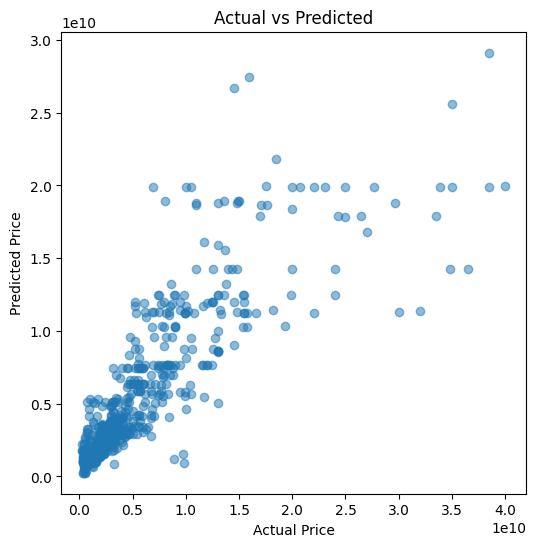

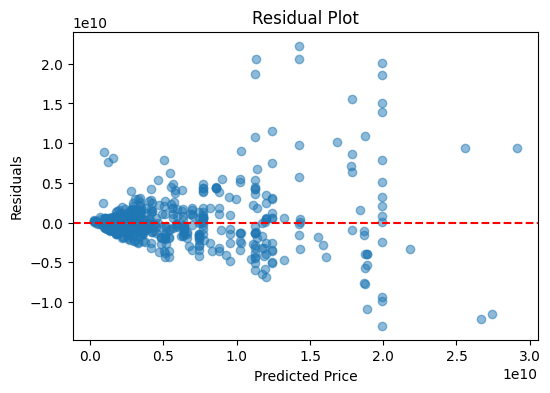

In [20]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.show()

residuals = y_test - y_pred

plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()